# 06. Доп. задание 1 - сильный дисбаланс классов

**Датасет:** Give Me Some Credit (Kaggle, 2011) - 150 000 заёмщиков, таргет `SeriousDlqin2yrs`
(просрочка 90+ дней в течение двух лет). Доля дефолтов ≈ 6.7% - сильный дисбаланс (1 : 14).

**Что проверяем экспериментально:**

1. Accuracy при дисбалансе бесполезна; ROC-AUC может быть обманчив - сравниваем с PR-AUC, MCC, Balanced Accuracy, F1 по классу 1.
2. Порог 0.5 не оптимален - подбираем порог под max F1, заданный Recall и минимум **бизнес-стоимости**.
3. Работа с классами: `class_weight`, `scale_pos_weight` / `is_unbalance`, `sample_weight`, SMOTE, ADASYN, SMOTEENN, undersampling.
4. Калибровка: reliability diagram, Brier score, log loss, Platt scaling и Isotonic regression.
5. Двухстадийный подход: фильтр с высокой полнотой -> модель на подмножестве.

**Бизнес-стоимость ошибок (допущение работы).** Пропущенный дефолт (FN) - банк теряет тело кредита;
ложный отказ (FP) - банк теряет только процентный доход по хорошему клиенту. Принимаем
**C_FN = 10, C_FP = 1** (в условных единицах). Метрика стоимости - средняя стоимость ошибок на одного клиента.

**Протокол:** train/test 80/20 со стратификацией. Всё, что «учится» (заполнение пропусков, масштаб, ресемплинг,
порог, калибровка), подбирается **только на train**: порог - по out-of-fold предсказаниям 5-фолдовой CV,
ресемплинг - внутри каждого фолда (`imblearn.Pipeline` применяет сэмплер только при `fit`). Тест - одна финальная оценка.

In [1]:
import sys
from pathlib import Path

KAGGLE_CONFIG_PATHS = [
    Path("/kaggle/input/project-config"),
    Path("/kaggle/input/kirylloffix/project-config"),
]

for p in KAGGLE_CONFIG_PATHS:
    if p.exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))
        break

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin, clone

from config import Config


warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

config = Config()
RANDOM_STATE = config.RANDOM_STATE
np.random.seed(RANDOM_STATE)
print(config)

Config(mode='local', credit='/home/claude/proj/data/credit_risk_dataset.csv', churn='/home/claude/proj/data/WA_Fn-UseC_-Telco-Customer-Churn.csv', demand='/home/claude/proj/data/train.csv', random_state=42)


In [2]:
DATASET = 'imbalance'
C_FN, C_FP = 10.0, 1.0

RENAME = {
    'SeriousDlqin2yrs': 'default',
    'RevolvingUtilizationOfUnsecuredLines': 'util',
    'age': 'age',
    'NumberOfTime30-59DaysPastDueNotWorse': 'late_30_59',
    'DebtRatio': 'debt_ratio',
    'MonthlyIncome': 'income',
    'NumberOfOpenCreditLinesAndLoans': 'open_lines',
    'NumberOfTimes90DaysLate': 'late_90',
    'NumberRealEstateLoansOrLines': 're_loans',
    'NumberOfTime60-89DaysPastDueNotWorse': 'late_60_89',
    'NumberOfDependents': 'dependents',
}
LATE = ['late_30_59', 'late_60_89', 'late_90']

df_raw = pd.read_csv(config.path_imbalance, index_col=0).rename(columns=RENAME)
print(df_raw.shape)
df_raw.head()

(150000, 11)


,default,util,age,late_30_59,debt_ratio,income,open_lines,late_90,re_loans,late_60_89,dependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


## 1. Диагностика дисбаланса и качества данных

In [3]:
y_all = df_raw['default']
p1 = y_all.mean()
print(f"доля класса 1: {p1:.4f}  (1 : {(1 - p1) / p1:.1f})")
print(f"Accuracy константы «всегда 0»: {1 - p1:.4f} - при нулевой пользе (не найден ни один дефолт)")

print("\nНеправильные значения:")
print(f"  age < 18:                      {(df_raw['age'] < 18).sum()}")
for c in LATE:
    print(f"  {c:12} коды 96/98:        {df_raw[c].isin([96, 98]).sum()}   (обычный максимум: {df_raw.loc[~df_raw[c].isin([96, 98]), c].max()})")
print(f"  util > 10 (использование лимита > 1000%): {(df_raw['util'] > 10).sum()}")
print(f"  полных дубликатов:             {df_raw.duplicated().sum()}")

print("\nПропуски и доля дефолтов среди них:")
for c in ['income', 'dependents']:
    m = df_raw[c].isna()
    print(f"  {c:11} NaN {m.sum():6d}  доля дефолтов {df_raw.loc[m, 'default'].mean():.4f}")
print(f"  debt_ratio > 1 при пропуске дохода: {((df_raw['debt_ratio'] > 1) & df_raw['income'].isna()).sum()} из {df_raw['income'].isna().sum()}"
      " -> без дохода в debt_ratio записан сам долг, а не отношение")
print("\nМедиана дохода по возрастным группам:",
      df_raw.groupby(pd.cut(df_raw['age'], [0, 30, 40, 50, 60, 70, 120]), observed=True)['income'].median().to_dict())

доля класса 1: 0.0668  (1 : 14.0)
Accuracy константы «всегда 0»: 0.9332 - при нулевой пользе (не найден ни один дефолт)

Неправильные значения:
  age < 18:                      1
  late_30_59   коды 96/98:        269   (обычный максимум: 13)
  late_60_89   коды 96/98:        269   (обычный максимум: 11)
  late_90      коды 96/98:        269   (обычный максимум: 17)
  util > 10 (использование лимита > 1000%): 241
  полных дубликатов:             609

Пропуски и доля дефолтов среди них:
  income      NaN  29731  доля дефолтов 0.0561
  dependents  NaN   3924  доля дефолтов 0.0456
  debt_ratio > 1 при пропуске дохода: 27904 из 29731 -> без дохода в debt_ratio записан сам долг, а не отношение



Медиана дохода по возрастным группам: {Interval(0, 30, closed='right'): 2779.5, Interval(30, 40, closed='right'): 4928.0, Interval(40, 50, closed='right'): 6041.0, Interval(50, 60, closed='right'): 6307.5, Interval(60, 70, closed='right'): 5833.0, Interval(70, 120, closed='right'): 4500.0}


**Правила очистки** (фиксированные, до разбиения - утечки нет):

- полные дубликаты удаляем;
- `age < 18` -> `NaN` (заёмщик не может быть младше 18);
- коды **96 / 98** в счётчиках просрочек - служебные значения («нет данных / отказ»), а не 96 просрочек ->
  `NaN` + флаг `late_code`. У всех таких строк коды стоят одновременно во всех трёх колонках;
- `util > 10` -> `NaN` (использование кредитного лимита больше 1000% - ошибка);
- `debt_ratio` при пропущенном доходе не является отношением -> `NaN` + флаг пропуска дохода.

**Условное заполнение** (внутри `Pipeline`, медианы считаются на train-фолде): доход и число иждивенцев -
медиана внутри возрастной группы (медиана дохода растёт от 2.8 тыс. у молодых до 6.3 тыс. в 50-60 лет);
остальные - глобальная медиана train.

In [4]:
df = df_raw.drop_duplicates().reset_index(drop=True)
print(f"удалено дубликатов: {len(df_raw) - len(df)}")

df['late_code'] = df[LATE].isin([96, 98]).any(axis=1).astype(int)
df.loc[df['age'] < 18, 'age'] = np.nan
for c in LATE:
    df.loc[df[c].isin([96, 98]), c] = np.nan
df.loc[df['util'] > 10, 'util'] = np.nan
df.loc[df['income'].isna(), 'debt_ratio'] = np.nan

X = df.drop(columns=['default'])
y = df['default'].astype(int)
print("пропуски после правил:")
print(X.isna().sum()[lambda s: s > 0])

удалено дубликатов: 609
пропуски после правил:
util            241
age               1
late_30_59      225
debt_ratio    29221
income        29221
late_90         225
late_60_89      225
dependents     3828
dtype: int64


In [5]:
class ConditionalMedianImputer(BaseEstimator, TransformerMixin):
    """Медиана внутри группы (как в 02_credit); пустой список групп -> глобальная медиана."""

    def __init__(self, rules, bins=None, indicators=None):
        self.rules = rules
        self.bins = bins
        self.indicators = indicators

    def _add_bins(self, X):
        X = X.copy()
        for col, edges in self.bin_edges_.items():
            X[f'{col}_bin'] = pd.cut(X[col], edges, labels=False, include_lowest=True)
        return X

    def fit(self, X, y=None):
        self.bin_edges_ = {}
        for col, q in (self.bins or {}).items():
            edges = np.unique(np.quantile(X[col].dropna(), np.linspace(0, 1, q + 1)))
            edges[0], edges[-1] = -np.inf, np.inf
            self.bin_edges_[col] = edges
        Xb = self._add_bins(X)
        self.group_medians_, self.global_medians_ = {}, {}
        for target, groups in self.rules.items():
            self.global_medians_[target] = Xb[target].median()
            if groups:
                self.group_medians_[target] = Xb.groupby(groups)[target].median().rename('_median').reset_index()
        return self

    def transform(self, X):
        Xb = self._add_bins(X)
        out = X.copy()
        for col in (self.indicators or []):
            out[f'{col}_was_missing'] = X[col].isna().astype(int)
        for target, groups in self.rules.items():
            mask = out[target].isna()
            if not mask.any():
                continue
            if groups:
                fill = (Xb.loc[mask, groups].merge(self.group_medians_[target], on=groups, how='left')['_median']
                        .to_numpy(dtype=float))
                fill = np.where(np.isnan(fill), self.global_medians_[target], fill)
            else:
                fill = self.global_medians_[target]
            out.loc[mask, target] = fill
        return out


def make_imputer():
    return ConditionalMedianImputer(
        rules={'age': [], 'income': ['age_bin'], 'dependents': ['age_bin'], 'util': [],
               'debt_ratio': ['age_bin'], 'late_30_59': [], 'late_60_89': [], 'late_90': []},
        bins={'age': 6},
        indicators=['income', 'dependents'],
    )

## 2. Разбиение и модели

**Признаки для линейной модели:** `log1p` к тяжёлым хвостам (доход, долг, использование лимита, счётчики) + `StandardScaler`.
Деревьям масштаб не нужен - для LightGBM признаки идут как есть.

**Конфигурации** (все - на одинаковых фолдах):

| Группа | Конфигурация |
|---|---|
| Бейзлайн | `Dummy` - всегда класс 0 |
| LogReg | без весов; `class_weight='balanced'`; SMOTE; ADASYN; SMOTEENN; RandomUnderSampler |
| LightGBM | без весов; `scale_pos_weight = n0/n1`; `is_unbalance=True`; `sample_weight` = стоимость ошибки (10 для класса 1); SMOTE; RandomUnderSampler |

Ресемплинг - шаг `imblearn.Pipeline`: он вызывается **только при обучении** на train-фолде, валидационный фолд и тест
остаются с исходным распределением классов.

In [6]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from lightgbm import LGBMClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.combine import SMOTEENN
from imblearn.under_sampling import RandomUnderSampler

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"train {X_train.shape}, test {X_test.shape}, доля класса 1: train {y_train.mean():.4f}, test {y_test.mean():.4f}")

SPW = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = n0 / n1 = {SPW:.2f}")

LOG_COLS = ['util', 'debt_ratio', 'income', 'open_lines', 're_loans', 'dependents'] + LATE


def log_heavy(X):
    X = X.copy()
    X[LOG_COLS] = np.log1p(X[LOG_COLS].clip(lower=0))
    return X


def lgbm(**kw):
    params = dict(n_estimators=400, learning_rate=0.03, num_leaves=31, min_child_samples=50,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                  random_state=RANDOM_STATE, n_jobs=1, verbose=-1)
    params.update(kw)
    return LGBMClassifier(**params)


def linear_pipe(model, sampler=None):
    steps = [('impute', make_imputer()), ('log', FunctionTransformer(log_heavy)), ('scale', StandardScaler())]
    if sampler is not None:
        steps.append(('sampler', sampler))
    steps.append(('model', model))
    return ImbPipeline(steps)


def tree_pipe(model, sampler=None):
    steps = [('impute', make_imputer())]
    if sampler is not None:
        steps.append(('sampler', sampler))
    steps.append(('model', model))
    return ImbPipeline(steps)


LR = lambda **kw: LogisticRegression(max_iter=2000, random_state=RANDOM_STATE, **kw)
RS = RANDOM_STATE

CONFIGS = {
    'Dummy':              (linear_pipe(DummyClassifier(strategy='prior')), None),
    'LogReg':             (linear_pipe(LR()), None),
    'LogReg_balanced':    (linear_pipe(LR(class_weight='balanced')), None),
    'LogReg_SMOTE':       (linear_pipe(LR(), SMOTE(random_state=RS)), None),
    'LogReg_ADASYN':      (linear_pipe(LR(), ADASYN(random_state=RS)), None),
    'LogReg_SMOTEENN':    (linear_pipe(LR(), SMOTEENN(random_state=RS)), None),
    'LogReg_under':       (linear_pipe(LR(), RandomUnderSampler(random_state=RS)), None),
    'LGBM':               (tree_pipe(lgbm()), None),
    'LGBM_spw':           (tree_pipe(lgbm(scale_pos_weight=SPW)), None),
    'LGBM_is_unbalance':  (tree_pipe(lgbm(is_unbalance=True)), None),
    'LGBM_sample_weight': (tree_pipe(lgbm()), 'cost'),
    'LGBM_SMOTE':         (tree_pipe(lgbm(), SMOTE(random_state=RS)), None),
    'LGBM_under':         (tree_pipe(lgbm(), RandomUnderSampler(random_state=RS)), None),
}
print("конфигураций:", len(CONFIGS))

train (119512, 11), test (29879, 11), доля класса 1: train 0.0670, test 0.0670
scale_pos_weight = n0 / n1 = 13.93
конфигураций: 13


### Out-of-fold предсказания на train и финальная модель

Для каждой конфигурации:

- `cross_val_predict` (StratifiedKFold(5)) -> вероятности для **каждого** объекта train, предсказанные моделью,
  которая его не видела. На них подбираются порог и калибровка;
- модель обучается на всём train -> вероятности на тесте.

`sample_weight` передаётся через `params={'model__sample_weight': w}` - sklearn сам режет веса по фолдам.

In [7]:
import time

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof, test_proba, fitted = {}, {}, {}

w_train = np.where(y_train == 1, C_FN / C_FP, 1.0)

for name, (pipe, weights) in CONFIGS.items():
    t0 = time.time()
    params = {'model__sample_weight': w_train} if weights == 'cost' else {}
    oof[name] = cross_val_predict(clone(pipe), X_train, y_train, cv=cv5, method='predict_proba',
                                  n_jobs=-1, params=params)[:, 1]
    est = clone(pipe).fit(X_train, y_train, **params)
    fitted[name] = est
    test_proba[name] = est.predict_proba(X_test)[:, 1]
    print(f"{name:20} готово за {time.time() - t0:5.0f} c, средняя вероятность на тесте {test_proba[name].mean():.4f}")

Dummy                готово за     2 c, средняя вероятность на тесте 0.0670


LogReg               готово за     1 c, средняя вероятность на тесте 0.0684


LogReg_balanced      готово за     1 c, средняя вероятность на тесте 0.3411


LogReg_SMOTE         готово за     3 c, средняя вероятность на тесте 0.3383


LogReg_ADASYN        готово за    19 c, средняя вероятность на тесте 0.3785


...

LGBM_spw             готово за    25 c, средняя вероятность на тесте 0.3069


LGBM_is_unbalance    готово за    26 c, средняя вероятность на тесте 0.3069


LGBM_sample_weight   готово за    27 c, средняя вероятность на тесте 0.2656


LGBM_SMOTE           готово за    57 c, средняя вероятность на тесте 0.1060


LGBM_under           готово за    10 c, средняя вероятность на тесте 0.3268


## 3. Метрики при пороге 0.5 - рейтинг зависит от метрики

- **ROC-AUC, PR-AUC (average precision), Brier, LogLoss** - не зависят от порога (считаются по вероятностям);
- **Accuracy, Balanced Accuracy, F1 (класс 1), MCC, Precision, Recall, Cost** - по меткам при пороге.

PR-AUC случайной модели = доле класса 1 (≈ 0.067), а не 0.5 как у ROC-AUC.

In [8]:
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, log_loss,
                             accuracy_score, balanced_accuracy_score, f1_score, matthews_corrcoef,
                             precision_score, recall_score, confusion_matrix)


def cost_per_client(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return (C_FN * fn + C_FP * fp) / len(y_true)


def threshold_metrics(y_true, proba, thr):
    pred = (proba >= thr).astype(int)
    return {
        'Accuracy': accuracy_score(y_true, pred),
        'BalancedAcc': balanced_accuracy_score(y_true, pred),
        'F1': f1_score(y_true, pred, zero_division=0),
        'MCC': matthews_corrcoef(y_true, pred),
        'Precision': precision_score(y_true, pred, zero_division=0),
        'Recall': recall_score(y_true, pred),
        'Cost': cost_per_client(y_true, pred),
    }


def prob_metrics(y_true, proba):
    p = np.clip(proba, 1e-6, 1 - 1e-6)
    return {'ROC-AUC': roc_auc_score(y_true, proba), 'PR-AUC': average_precision_score(y_true, proba),
            'Brier': brier_score_loss(y_true, proba), 'LogLoss': log_loss(y_true, p)}


rows = []
for name in CONFIGS:
    rows.append({'model': name, **prob_metrics(y_test, test_proba[name]), **threshold_metrics(y_test, test_proba[name], 0.5)})
m05 = pd.DataFrame(rows).set_index('model')
m05.to_csv(config.RESULTS_DIR / 'imbalance_metrics_thr05.csv')

pd.set_option('display.width', 250)
print("ТЕСТ, порог 0.5:")
print(m05.round(4))

ТЕСТ, порог 0.5:
                    ROC-AUC  PR-AUC   Brier  LogLoss  Accuracy  BalancedAcc      F1     MCC  Precision  Recall    Cost
model                                                                                                                 
Dummy                0.5000  0.0670  0.0625   0.2458    0.9330       0.5000  0.0000  0.0000     0.0000  0.0000  0.6700
LogReg               0.8527  0.3870  0.0503   0.1841    0.9367       0.5950  0.2979  0.3162     0.5812  0.2003  0.5455
LogReg_balanced      0.8543  0.3895  0.1471   0.4826    0.8011       0.7757  0.3346  0.3266     0.2156  0.7463  0.3519
LogReg_SMOTE         0.8539  0.3887  0.1469   0.4801    0.7992       0.7769  0.3339  0.3269     0.2147  0.7512  0.3508
LogReg_ADASYN        0.8530  0.3862  0.1697   0.5341    0.7607       0.7726  0.3057  0.3043     0.1898  0.7862  0.3682
LogReg_SMOTEENN      0.8555  0.3898  0.1821   0.6569    0.7476       0.7748  0.2997  0.3018     0.1841  0.8062  0.3693
LogReg_under         0.8545  0.

In [9]:
HIGHER = {'ROC-AUC': True, 'PR-AUC': True, 'Brier': False, 'LogLoss': False, 'Accuracy': True,
          'BalancedAcc': True, 'F1': True, 'MCC': True, 'Recall': True, 'Cost': False}

ranks = pd.DataFrame({m: m05[m].rank(ascending=not HIGHER[m], method='min') for m in HIGHER}).astype(int)
ranks.to_csv(config.RESULTS_DIR / 'imbalance_ranks_thr05.csv')
print("Ранг конфигурации по каждой метрике (1 - лучшая), тест, порог 0.5:")
print(ranks)
print()
for m in HIGHER:
    print(f"{m:12} лучшая: {ranks[m].idxmin()}")

Ранг конфигурации по каждой метрике (1 - лучшая), тест, порог 0.5:
                    ROC-AUC  PR-AUC  Brier  LogLoss  Accuracy  BalancedAcc  F1  MCC  Recall  Cost
model                                                                                            
Dummy                    13      13      4        4         3           13  13   13      13    13
LogReg                   11      10      2        2         2           11  11   10      11    11
LogReg_balanced           8       7     10       11         8            7   5    7       8     7
LogReg_SMOTE              9       9      8        9        10            5   7    6       6     5
LogReg_ADASYN            10      11     12       12        12            9   9   11       2     8
LogReg_SMOTEENN           6       6     13       13        13            8  10   12       1     9
LogReg_under              7       8      9       10         9            6   4    5       7     5
LGBM                      1       3      1        1

### ROC- и PR-кривые

ROC-кривые лучших моделей почти совпадают, а PR-кривые показывают реальную разницу в той области,
где модель называет класс 1: при Recall 0.5 Precision падает до ~0.4-0.5.

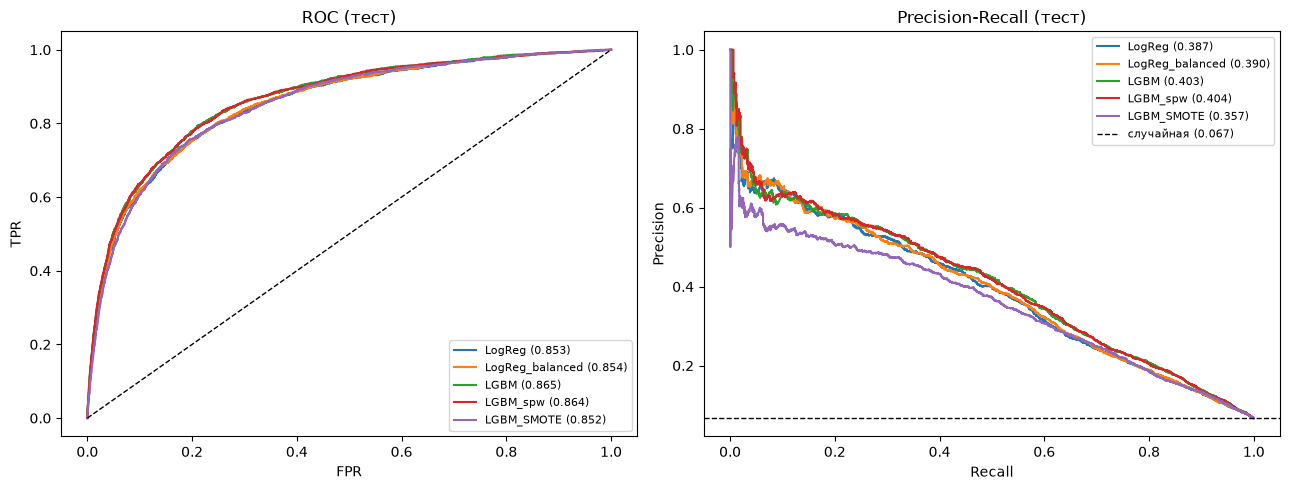

In [10]:
from sklearn.metrics import roc_curve, precision_recall_curve

SHOW = ['LogReg', 'LogReg_balanced', 'LGBM', 'LGBM_spw', 'LGBM_SMOTE']
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in SHOW:
    fpr, tpr, _ = roc_curve(y_test, test_proba[name])
    pr, rc, _ = precision_recall_curve(y_test, test_proba[name])
    axes[0].plot(fpr, tpr, label=f"{name} ({m05.loc[name, 'ROC-AUC']:.3f})")
    axes[1].plot(rc, pr, label=f"{name} ({m05.loc[name, 'PR-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].axhline(y_test.mean(), color='k', ls='--', lw=1, label=f'случайная ({y_test.mean():.3f})')
axes[0].set(title='ROC (тест)', xlabel='FPR', ylabel='TPR')
axes[1].set(title='Precision-Recall (тест)', xlabel='Recall', ylabel='Precision')
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(config.RESULTS_DIR / 'imbalance_roc_pr.png', dpi=150)
plt.show()

## 4. Подбор порога

Порог подбирается **на out-of-fold вероятностях train**, затем применяется к тесту. Три правила:

1. **max F1** на OOF;
2. **Recall ≥ 0.80** - наибольший порог, при котором OOF-recall ≥ 0.8 (например, требование регулятора/риск-менеджмента);
3. **min Cost** - минимум средней стоимости `(10·FN + 1·FP) / n` на OOF.

**Теория:** если вероятности **откалиброваны**, оптимальный по стоимости порог равен
t* = C_FP / (C_FP + C_FN) = 1/11 ≈ 0.091 (решающее правило Байеса).

In [11]:
THRESHOLDS = np.linspace(0.01, 0.99, 197)


def pick_thresholds(y_true, proba):
    f1s, costs, recalls = [], [], []
    for t in THRESHOLDS:
        pred = (proba >= t).astype(int)
        f1s.append(f1_score(y_true, pred, zero_division=0))
        costs.append(cost_per_client(y_true, pred))
        recalls.append(recall_score(y_true, pred))
    f1s, costs, recalls = map(np.array, (f1s, costs, recalls))
    ok = np.where(recalls >= 0.80)[0]
    return {'thr_maxF1': THRESHOLDS[f1s.argmax()],
            'thr_recall80': THRESHOLDS[ok.max()] if len(ok) else np.nan,
            'thr_minCost': THRESHOLDS[costs.argmin()]}, costs


thr_rows, cost_curves = [], {}
for name in CONFIGS:
    if name == 'Dummy':
        continue
    thr, cost_curves[name] = pick_thresholds(y_train, oof[name])
    row = {'model': name, **thr}
    for rule, t in thr.items():
        tm = threshold_metrics(y_test, test_proba[name], t)
        row[f'{rule}_F1'] = tm['F1']
        row[f'{rule}_Recall'] = tm['Recall']
        row[f'{rule}_Precision'] = tm['Precision']
        row[f'{rule}_Cost'] = tm['Cost']
        row[f'{rule}_MCC'] = tm['MCC']
    row['Cost_at_0.5'] = m05.loc[name, 'Cost']
    row['PR-AUC'] = m05.loc[name, 'PR-AUC']
    thr_rows.append(row)

thr_df = pd.DataFrame(thr_rows).set_index('model').sort_values('thr_minCost_Cost')
thr_df.to_csv(config.RESULTS_DIR / 'imbalance_thresholds.csv')

print("Пороги (подобраны на OOF train):")
print(thr_df[['thr_maxF1', 'thr_recall80', 'thr_minCost']].round(3))
print("\nТЕСТ: стоимость на клиента при пороге 0.5 и при пороге min Cost; F1 при пороге max F1:")
print(thr_df[['Cost_at_0.5', 'thr_minCost_Cost', 'thr_minCost_Recall', 'thr_minCost_Precision',
              'thr_maxF1_F1', 'thr_recall80_Recall', 'thr_recall80_Precision', 'PR-AUC']].round(4))
print(f"\nDummy (всегда 0): стоимость {m05.loc['Dummy', 'Cost']:.4f} на клиента")

Пороги (подобраны на OOF train):
                    thr_maxF1  thr_recall80  thr_minCost
model                                                   
LGBM_sample_weight      0.700         0.355        0.460
LGBM_under              0.800         0.460        0.605
LGBM                    0.215         0.055        0.085
LGBM_spw                0.795         0.435        0.545
LGBM_is_unbalance       0.795         0.435        0.550
LGBM_SMOTE              0.315         0.105        0.150
LogReg_balanced         0.780         0.425        0.565
LogReg_SMOTEENN         0.920         0.500        0.735
LogReg_SMOTE            0.775         0.425        0.575
LogReg_ADASYN           0.785         0.475        0.615
LogReg_under            0.755         0.430        0.550
LogReg                  0.160         0.050        0.085

ТЕСТ: стоимость на клиента при пороге 0.5 и при пороге min Cost; F1 при пороге max F1:
                    Cost_at_0.5  thr_minCost_Cost  thr_minCost_Recall  thr_minCos

### Кривая «порог -> стоимость»

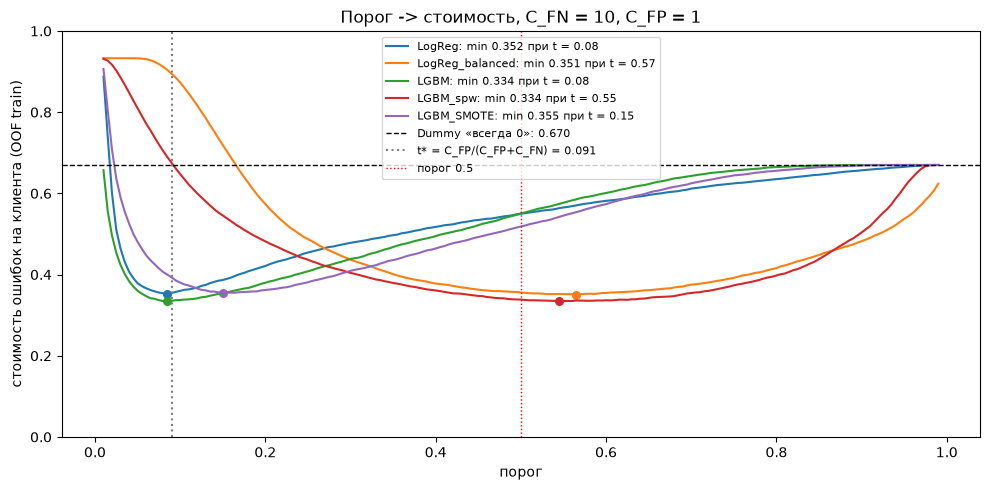

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))
for name in ['LogReg', 'LogReg_balanced', 'LGBM', 'LGBM_spw', 'LGBM_SMOTE']:
    c = cost_curves[name]
    ax.plot(THRESHOLDS, c, label=f"{name}: min {c.min():.3f} при t = {THRESHOLDS[c.argmin()]:.2f}")
    ax.scatter(THRESHOLDS[c.argmin()], c.min(), s=30)
ax.axhline(y_train.mean() * C_FN, color='k', ls='--', lw=1, label=f'Dummy «всегда 0»: {y_train.mean() * C_FN:.3f}')
ax.axvline(C_FP / (C_FP + C_FN), color='grey', ls=':', lw=1.5, label='t* = C_FP/(C_FP+C_FN) = 0.091')
ax.axvline(0.5, color='red', ls=':', lw=1, label='порог 0.5')
ax.set(xlabel='порог', ylabel='стоимость ошибок на клиента (OOF train)',
       title=f'Порог -> стоимость, C_FN = {C_FN:.0f}, C_FP = {C_FP:.0f}', ylim=(0, 1.0))
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(config.RESULTS_DIR / 'imbalance_threshold_cost.png', dpi=150)
plt.show()

### Чувствительность к соотношению стоимостей

Оптимальный порог LightGBM (без весов) на OOF для разных C_FN / C_FP и теоретический порог 1 / (1 + C_FN / C_FP).

In [13]:
sens = []
for ratio in [2, 5, 10, 20, 50]:
    costs = [((oof['LGBM'] >= t) & (y_train == 0)).sum() * 1 + ((oof['LGBM'] < t) & (y_train == 1)).sum() * ratio
             for t in THRESHOLDS]
    sens.append({'C_FN/C_FP': ratio, 'порог OOF': THRESHOLDS[int(np.argmin(costs))], 'теория 1/(1+r)': 1 / (1 + ratio)})
sens_df = pd.DataFrame(sens)
sens_df.to_csv(config.RESULTS_DIR / 'imbalance_cost_sensitivity.csv', index=False)
print(sens_df.round(3))

   C_FN/C_FP  порог OOF  теория 1/(1+r)
0          2      0.330           0.333
1          5      0.180           0.167
2         10      0.085           0.091
3         20      0.045           0.048
4         50      0.020           0.020


## 5. Калибровка вероятностей

**Reliability diagram:** объекты делятся на 10 корзин по предсказанной вероятности (по квантилям), в каждой сравнивается
средняя предсказанная вероятность и реальная доля дефолтов. Идеал - диагональ.

**Brier score** = среднее (p − y)², **log loss** = −среднее [y·log p + (1−y)·log(1−p)] - чем меньше, тем лучше.

Калибруем `CalibratedClassifierCV(cv=3)` на train: **Platt scaling** (`sigmoid` - логистическая функция поверх оценок)
и **Isotonic regression** (монотонная ступенчатая функция).

In [14]:
from sklearn.calibration import calibration_curve, CalibratedClassifierCV

CAL_BASE = ['LGBM', 'LGBM_spw', 'LGBM_SMOTE', 'LogReg_balanced']
cal_proba = {}
for name in CAL_BASE:
    pipe, weights = CONFIGS[name]
    for method in ['sigmoid', 'isotonic']:
        cal = CalibratedClassifierCV(clone(pipe), method=method, cv=3, n_jobs=-1)
        cal.fit(X_train, y_train)
        cal_proba[f'{name}+{method}'] = cal.predict_proba(X_test)[:, 1]

cal_rows = []
for name in CAL_BASE:
    for key, proba in [(name, test_proba[name]), (f'{name}+sigmoid', cal_proba[f'{name}+sigmoid']),
                       (f'{name}+isotonic', cal_proba[f'{name}+isotonic'])]:
        cal_rows.append({'model': key, 'mean_proba': proba.mean(), **prob_metrics(y_test, proba),
                         'Cost@t*': threshold_metrics(y_test, proba, C_FP / (C_FP + C_FN))['Cost']})
cal_df = pd.DataFrame(cal_rows).set_index('model')
cal_df.to_csv(config.RESULTS_DIR / 'imbalance_calibration.csv')
print(f"реальная доля класса 1 на тесте: {y_test.mean():.4f}")
print(cal_df.round(4))

реальная доля класса 1 на тесте: 0.0670
                          mean_proba  ROC-AUC  PR-AUC   Brier  LogLoss  Cost@t*
model                                                                          
LGBM                          0.0686   0.8645  0.4026  0.0488   0.1774   0.3340
LGBM+sigmoid                  0.0688   0.8647  0.4041  0.0488   0.1772   0.3332
LGBM+isotonic                 0.0688   0.8645  0.4012  0.0488   0.1775   0.3329
LGBM_spw                      0.3069   0.8639  0.4041  0.1388   0.4333   0.6965
LGBM_spw+sigmoid              0.0687   0.8647  0.4036  0.0488   0.1775   0.3341
LGBM_spw+isotonic             0.0687   0.8645  0.4003  0.0488   0.1775   0.3332
LGBM_SMOTE                    0.1060   0.8521  0.3572  0.0535   0.1961   0.3972
LGBM_SMOTE+sigmoid            0.0684   0.8526  0.3616  0.0507   0.1841   0.3444
LGBM_SMOTE+isotonic           0.0684   0.8523  0.3607  0.0506   0.1838   0.3444
LogReg_balanced               0.3411   0.8543  0.3895  0.1471   0.4826   0.8934


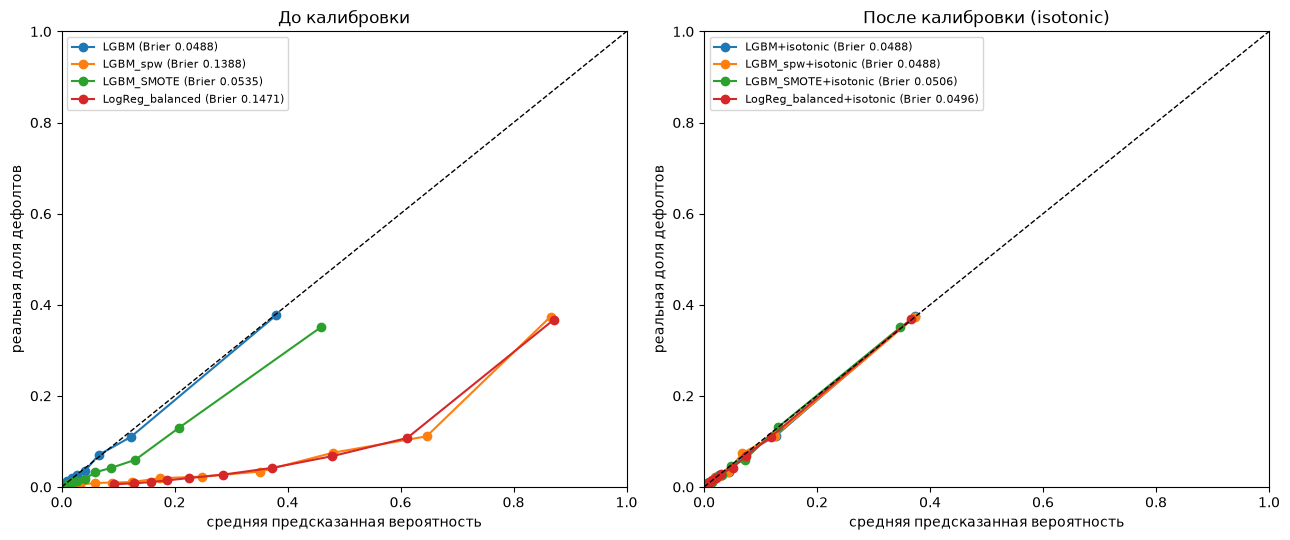

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for name in CAL_BASE:
    fp, mp = calibration_curve(y_test, test_proba[name], n_bins=10, strategy='quantile')
    axes[0].plot(mp, fp, 'o-', label=f"{name} (Brier {cal_df.loc[name, 'Brier']:.4f})")
    key = f'{name}+isotonic'
    fp, mp = calibration_curve(y_test, cal_proba[key], n_bins=10, strategy='quantile')
    axes[1].plot(mp, fp, 'o-', label=f"{key} (Brier {cal_df.loc[key, 'Brier']:.4f})")
for ax, title in zip(axes, ['До калибровки', 'После калибровки (isotonic)']):
    ax.plot([0, 1], [0, 1], 'k--', lw=1)
    ax.set(xlabel='средняя предсказанная вероятность', ylabel='реальная доля дефолтов', title=title,
           xlim=(0, 1), ylim=(0, 1))
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(config.RESULTS_DIR / 'imbalance_reliability.png', dpi=150)
plt.show()

## 6. Двухстадийный подход

1. **Стадия 1 - фильтр:** `LogReg_balanced` с порогом, дающим Recall ≥ 0.95 на OOF train. Отсекает очевидно «хороших» клиентов.
2. **Стадия 2:** LightGBM обучается **только на прошедших фильтр** объектах train (там доля дефолтов выше, дисбаланс мягче).
3. Итоговая вероятность = вероятность стадии 2 для прошедших фильтр и 0 для отсечённых.

Порог для стоимости стадии 2 подбирается на её OOF-вероятностях. Сравниваем с одностадийным LightGBM.

In [16]:
_, costs_lr = pick_thresholds(y_train, oof['LogReg_balanced'])
rec = np.array([recall_score(y_train, (oof['LogReg_balanced'] >= t).astype(int)) for t in THRESHOLDS])
t1 = THRESHOLDS[np.where(rec >= 0.95)[0].max()]

pass_tr = oof['LogReg_balanced'] >= t1
pass_te = test_proba['LogReg_balanced'] >= t1
print(f"порог стадии 1: {t1:.3f}")
print(f"train: проходит {pass_tr.mean():.3f} объектов, доля дефолтов среди них {y_train[pass_tr].mean():.4f} (было {y_train.mean():.4f})")
print(f"test:  проходит {pass_te.mean():.3f}, найдено дефолтов фильтром {y_test[pass_te].sum() / y_test.sum():.3f}")

stage2 = tree_pipe(lgbm())
X2, y2 = X_train[pass_tr], y_train[pass_tr]
oof2 = cross_val_predict(clone(stage2), X2, y2, cv=cv5, method='predict_proba', n_jobs=-1)[:, 1]
stage2.fit(X2, y2)

oof_two = np.zeros(len(y_train)); oof_two[pass_tr] = oof2
test_two = np.zeros(len(y_test)); test_two[pass_te] = stage2.predict_proba(X_test[pass_te])[:, 1]

thr_two, _ = pick_thresholds(y_train, oof_two)
two_rows = []
for name, o, p in [('LGBM (1 стадия)', oof['LGBM'], test_proba['LGBM']), ('Двухстадийная', oof_two, test_two)]:
    thr, _ = pick_thresholds(y_train, o)
    two_rows.append({'model': name, **prob_metrics(y_test, p), 'thr_minCost': thr['thr_minCost'],
                     **{k: v for k, v in threshold_metrics(y_test, p, thr['thr_minCost']).items() if k in ['Cost', 'F1', 'Recall', 'Precision', 'MCC']}})
two_df = pd.DataFrame(two_rows).set_index('model')
two_df.to_csv(config.RESULTS_DIR / 'imbalance_two_stage.csv')
print()
print(two_df.round(4))

порог стадии 1: 0.200
train: проходит 0.604 объектов, доля дефолтов среди них 0.1054 (было 0.0670)
test:  проходит 0.609, найдено дефолтов фильтром 0.944



                 ROC-AUC  PR-AUC   Brier  LogLoss  thr_minCost      F1     MCC  Precision  Recall    Cost
model                                                                                                    
LGBM (1 стадия)   0.8645  0.4026  0.0488   0.1774        0.085  0.3667  0.3545     0.2454  0.7253  0.3335
Двухстадийная     0.8609  0.4002  0.0489   0.2087        0.095  0.3802  0.3642     0.2601  0.7063  0.3314


## 7. Сводка для отчёта

In [17]:
summary = m05[['ROC-AUC', 'PR-AUC', 'Brier', 'Accuracy', 'F1', 'MCC', 'BalancedAcc', 'Cost']].copy()
summary.columns = [f'{c}@0.5' if c in ['Accuracy', 'F1', 'MCC', 'BalancedAcc', 'Cost'] else c for c in summary.columns]
summary = summary.join(thr_df[['thr_minCost', 'thr_minCost_Cost', 'thr_maxF1_F1']], how='left')
summary.to_csv(config.RESULTS_DIR / 'imbalance_summary.csv')
print(summary.sort_values('PR-AUC', ascending=False).round(4))

                    ROC-AUC  PR-AUC   Brier  Accuracy@0.5  F1@0.5  MCC@0.5  BalancedAcc@0.5  Cost@0.5  thr_minCost  thr_minCost_Cost  thr_maxF1_F1
model                                                                                                                                             
LGBM_spw             0.8639  0.4041  0.1388        0.8018  0.3423   0.3387           0.7869    0.3371        0.545            0.3343        0.4547
LGBM_is_unbalance    0.8639  0.4041  0.1388        0.8018  0.3423   0.3387           0.7869    0.3371        0.550            0.3358        0.4547
LGBM                 0.8645  0.4026  0.0488        0.9368  0.2977   0.3167           0.5948    0.5457        0.085            0.3335        0.4556
LGBM_sample_weight   0.8642  0.4012  0.1131        0.8448  0.3772   0.3605           0.7782    0.3353        0.460            0.3315        0.4530
LGBM_under           0.8621  0.3961  0.1509        0.7886  0.3320   0.3311           0.7866    0.3415        0.605    

## Выводы

**Данные.** 149 391 заёмщик после удаления 609 дубликатов; доля дефолтов 6.70% (1 : 14). Исправлены неправильные значения:
служебные коды 96/98 в счётчиках просрочек (269 строк), возраст 0, использование лимита > 1000% (241), `debt_ratio`
без дохода (это сумма долга, а не отношение). Train 119 512 / test 29 879.

### 1. Accuracy - мусорная метрика при дисбалансе

Константа «всегда 0» даёт Accuracy **0.9330** и не находит ни одного дефолта. Лучшая модель по Accuracy - LightGBM без весов
(0.9368, всего +0.4 п.п.), при этом по стоимости ошибок (порог 0.5) она почти так же плоха, как константа:
0.546 против 0.670 на клиента. Рейтинг по Accuracy обратен рейтингу по стоимости.

### 2. Рейтинг моделей зависит от метрики

Лучшая конфигурация (тест, порог 0.5): ROC-AUC, Brier, LogLoss, Accuracy - **LGBM**; PR-AUC и Balanced Accuracy - **LGBM_spw**;
F1, MCC и стоимость - **LGBM_sample_weight**; Recall - **LogReg_SMOTEENN**. ROC-AUC почти не различает модели
(0.852-0.865 у всех), PR-AUC - в 1.5 раза информативнее по шкале (0.357-0.404 при случайном уровне 0.067).
ROC-AUC обманчив: у LGBM ROC-AUC 0.865, но при пороге 0.5 Recall всего 0.20.

### 3. Порог 0.5 не оптимален - и это главный рычаг

После подбора порога на OOF train стоимость на тесте у всех LightGBM-вариантов **одинакова**: 0.3315-0.3358
(у LGBM без весов падает с 0.546 до 0.334). Стандартная ошибка средней стоимости на тесте ≈ 0.008, так что разница
между вариантами - шум. Вывод: `class_weight`, `scale_pos_weight`, `is_unbalance`, `sample_weight` и undersampling
**в основном сдвигают порог**; если порог подбирается, они почти ничего не дают. `scale_pos_weight` и `is_unbalance` дали
идентичные модели.

Оптимальный порог LGBM по стоимости (0.085) совпал с теоретическим t* = C_FP / (C_FP + C_FN) = 0.091; для
соотношений стоимостей 2, 5, 10, 20, 50 эмпирический порог (0.330, 0.180, 0.085, 0.045, 0.020) совпадает с теорией
1/(1+r) с точностью ±0.015.

### 4. Ресемплинг: отрицательный результат

- SMOTE / ADASYN / SMOTEENN для LogReg - тот же PR-AUC (0.386-0.390), что и `class_weight='balanced'` (0.390);
- SMOTE для LightGBM **ухудшил** качество: PR-AUC 0.357 против 0.403, стоимость после подбора порога 0.343 против 0.334.
  Синтетические точки интерполируют дискретные счётчики (0.37 иждивенца, 1.6 просрочки) и размывают границы деревьев;
- SMOTEENN обучался 704 с против 1-3 с у `class_weight` - без выигрыша.

### 5. Калибровка: гипотеза «бустинг плохо калиброван из коробки» не подтвердилась

LightGBM с log loss откалиброван хорошо: средняя вероятность 0.0686 при реальной доле 0.0670, Brier 0.0488;
Platt и isotonic его не улучшают. Калибровку **ломает перевзвешивание**: у LGBM_spw средняя вероятность 0.307, Brier 0.139,
у LogReg_balanced - 0.341 и 0.147. Platt / isotonic возвращают их к Brier 0.0488-0.0503, и после этого теоретический порог
t* = 0.091 даёт стоимость 0.333-0.347 вместо 0.697 (LGBM_spw) и 0.893 (LogReg_balanced).

### 6. Двухстадийный подход не помог

Фильтр (LogReg_balanced, порог 0.20) пропускает 61% клиентов и 94.4% дефолтов; доля дефолтов в подмножестве 10.5%.
Модель второй стадии: PR-AUC 0.400 против 0.403 у одностадийного LightGBM, стоимость 0.331 против 0.334 - в пределах шума.
Фильтр теряет 5.6% дефолтов, а LightGBM и так умеет игнорировать «лёгких» клиентов.

### Порядок действий

**Выбрать метрику под бизнес-стоимость (здесь C_FN = 10, C_FP = 1) -> подобрать порог на OOF train -> выбрать модель и
балансировку.** Если вероятности нужны как вероятности (резервы, ценообразование) - не перевзвешивать или калибровать.